In [1]:
## Aim: ##

In [2]:
## Cell 1 ##

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from opa import array_intensity

wl, N = 1.55e-6, 64
theta = np.radians(np.linspace(-90, 90, 7201)) # (m,n,o) Grid spaceing = 180/o-1. e.g: 1801: 0.1deg spacing.

In [4]:
# N - number of emitters

In [5]:
## Cell 2 ##

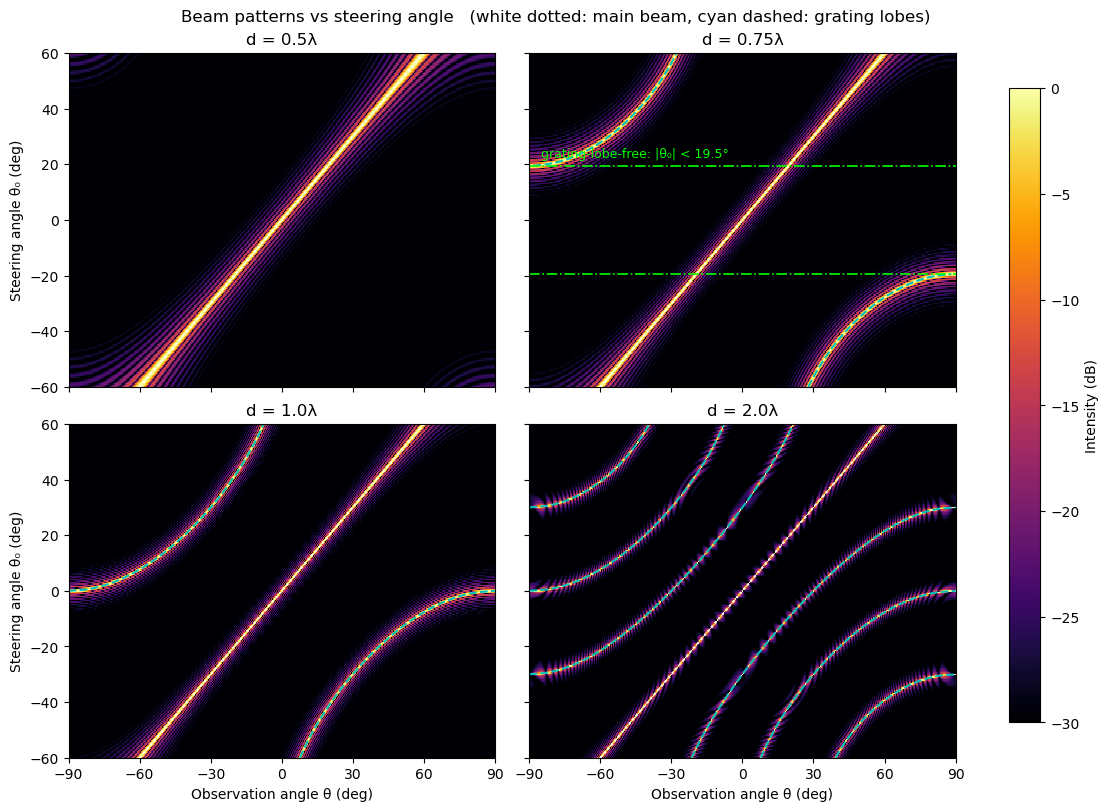

In [6]:
def steering_map(N, d, wl, theta, steer_deg):
    """Intensity vs observation angle for each steering angle (rows)."""
    rows = []
    for s in steer_deg:
        dphi = 2 * np.pi * d / wl * np.sin(np.radians(s))
        rows.append(array_intensity(theta, N, d, wl, dphi))
    return np.array(rows)

steer = np.linspace(-60, 60, 241)
ratios = [0.5, 0.75, 1.0, 2.0]                       # d/λ

fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True,
                         constrained_layout=True)

for ax, r in zip(axes.flat, ratios):
    I = steering_map(N, r * wl, wl, theta, steer)
    im = ax.pcolormesh(np.degrees(theta), steer, 10 * np.log10(I + 1e-12),
                       vmin=-30, vmax=0, shading="auto", cmap="inferno")

    # theory: beams where sin θ = sin θ0 + m λ/d
    s0 = np.sin(np.radians(steer))
    for m in range(-4, 5):
        s = s0 + m / r
        ok = np.abs(s) <= 1
        style = "w:" if m == 0 else "c--"            # main beam vs grating lobes
        ax.plot(np.degrees(np.arcsin(s[ok])), steer[ok], style, lw=1.5)

    # steering limit for a grating-lobe-free field of view (only for 0.5λ < d < λ)
    if 0.5 < r < 1:
        tmax = np.degrees(np.arcsin(1 / r - 1))
        for sign in (+1, -1):
            ax.axhline(sign * tmax, color="lime", ls="-.", lw=1.2)
        ax.text(-85, tmax + 2, f"grating-lobe-free: |θ₀| < {tmax:.1f}°",
                color="lime", fontsize=9, va="bottom")

    ax.set_title(f"d = {r}λ")
    ax.set_xlim(-90, 90); ax.set_ylim(-60, 60)
    ax.set_xticks(range(-90, 91, 30))

for ax in axes[1, :]:
    ax.set_xlabel("Observation angle θ (deg)")
for ax in axes[:, 0]:
    ax.set_ylabel("Steering angle θ₀ (deg)")

fig.colorbar(im, ax=axes, label="Intensity (dB)", shrink=0.9)
fig.suptitle("Beam patterns vs steering angle   (white dotted: main beam, cyan dashed: grating lobes)")
plt.show()

In [7]:
# Notes: Look at lobes, they get wider at greater steering angles (remember from part 1)
# Grating lobes curve for 0.75, 1 and 2 lambda. Pattern repeats evenly in sin(theta)
# Cyan lines: theory
# Further investigate: Effect of varying N


In [8]:
## Cell 3: field of view against spacing ##

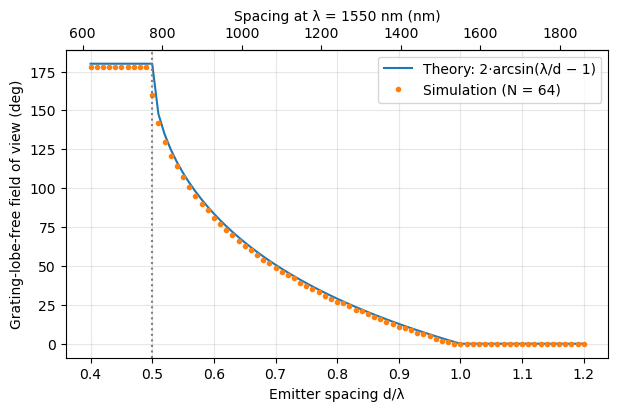

In [9]:
def has_grating_lobe(I, theta, theta0, N, d, wl, thresh=0.5):
    """True if any beam outside the main lobe exceeds -3 dB."""
    outside = np.abs(np.sin(theta) - np.sin(theta0)) > wl / (N * d)
    return I[outside].max() > thresh

ratios = np.linspace(0.4, 1.2, 81)
steer_fine = np.linspace(0, 89, 179)
numeric = []
for r in ratios:
    best = 0
    for s in steer_fine:
        dphi = 2 * np.pi * r * np.sin(np.radians(s))
        I = array_intensity(theta, N, r * wl, wl, dphi)
        if has_grating_lobe(I, theta, np.radians(s), N, r * wl, wl):
            break
        best = s
    numeric.append(best)

analytic = np.degrees(np.arcsin(np.clip(1 / ratios - 1, 0, 1)))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ratios, 2 * analytic, label="Theory: 2·arcsin(λ/d − 1)")
ax.plot(ratios, 2 * np.array(numeric), "o", ms=3, label=f"Simulation (N = {N})")
ax.axvline(0.5, color="grey", ls=":")
ax.set_xlabel("Emitter spacing d/λ"); ax.set_ylabel("Grating-lobe-free field of view (deg)")
top = ax.secondary_xaxis("top", functions=(lambda r: r * 1550, lambda nm: nm / 1550))
top.set_xlabel("Spacing at λ = 1550 nm (nm)")
ax.legend(); ax.grid(alpha=0.3); plt.show()

Notes: -3dB threshold. 
The simulation points sitting slightly below the theory curve.
Theory marks when the grating lobe’s centre enters view, but the lobe has a finite width, so its edge crosses the −3 dB threshold a little earlier.
Try N = 64 and the gap shrinks, because more emitters make narrower lobes. 

Grating-lobe-free field of view: range of steering angles θ₀ over which you can aim the beam without a grating lobe appearing at any observation angle from −90° to +90°

Qs:
    
1. What field of view do you get at d = λ/2, 0.75λ and λ?
2. Why are the grating-lobe lines in the map curved rather than straight? (Hint: the pattern repeats evenly in sin θ, not in θ.)
3. Why is the main beam narrower at d = 2λ, and what does that trade-off mean for a LIDAR designer?
4. Why is half-wavelength spacing hard to build on a silicon photonic chip? (Waveguides that close together leak light into each other.)

# Cell 4: If fabrication limits your emitter spacing to 1 µm at 1550 nm, how much field of view do you get?

In [10]:
d = 1.0e-6                      # 1 µm pitch
r = d / wl

theta_max_theory = np.degrees(np.arcsin(wl / d - 1))

best = 0
for s in np.arange(0, 90, 0.1):                      # fine steering steps
    dphi = 2 * np.pi * r * np.sin(np.radians(s))
    I = array_intensity(theta, N, d, wl, dphi)
    if has_grating_lobe(I, theta, np.radians(s), N, d, wl):
        break
    best = s

print(f"d/λ = {r:.3f}")
print(f"Theory:     θ_max = {theta_max_theory:.1f}°  →  FOV = {2*theta_max_theory:.1f}°")
print(f"Simulation: θ_max = {best:.1f}°  →  FOV = {2*best:.1f}°  (N = {N})")

d/λ = 0.645
Theory:     θ_max = 33.4°  →  FOV = 66.7°
Simulation: θ_max = 32.6°  →  FOV = 65.2°  (N = 64)


Simulation is lower than theory for same reason as before

Plotting the beam pattern at three steering angles: safely inside the limit, at the limit, and beyond it:

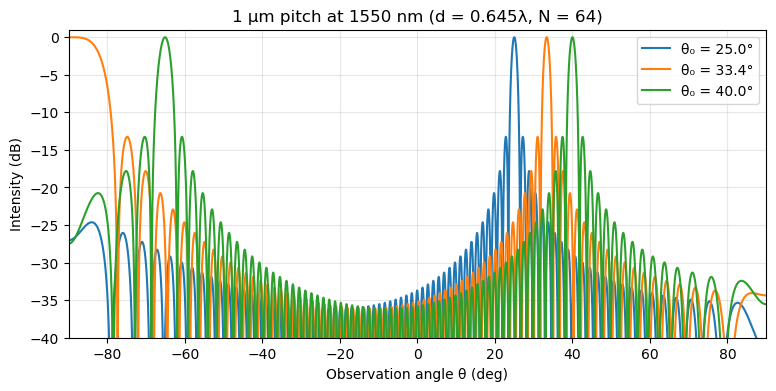

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
for s in [25, theta_max_theory, 40]:
    dphi = 2 * np.pi * r * np.sin(np.radians(s))
    I = array_intensity(theta, N, d, wl, dphi)
    ax.plot(np.degrees(theta), 10 * np.log10(I + 1e-12), label=f"θ₀ = {s:.1f}°")

ax.set_ylim(-40, 1); ax.set_xlim(-90, 90)
ax.set_xlabel("Observation angle θ (deg)"); ax.set_ylabel("Intensity (dB)")
ax.set_title(f"1 µm pitch at 1550 nm (d = {r:.3f}λ, N = {N})")
ax.legend(); ax.grid(alpha=0.3); plt.show()

θ₀ = 25°: only the main beam. The grating lobe would be at sin θ = 0.42 − 1.55 = −1.13, outside the visible range.
θ₀ = 33.4°: a grating lobe appears at the −90° edge.
θ₀ = 40°: a full-strength grating lobe at about −65° (sin θ = 0.64 − 1.55 = −0.91).

Interpretation: 
    
A pitch (emitter spacing) that’s easier to fabricate (1 µm instead of 775 nm) costs you more than half the field of view: about 67° instead of 180°.
That’s the core trade-off in silicon photonic phased arrays. Waveguides placed closer together leak light into each other, but wider spacing creates grating lobes.
Engineers work around this in several ways. One is non-uniform (aperiodic) emitter spacing, which breaks up the grating lobes. That’s a possible stretch goal for Part 4